# H08. 냉각기·축압기에는 LDA가 랜덤포레스트보다 나은가

| 항목 | 내용 |
|---|---|
| 질문 | 같은 문제를 풀게 했을 때 LDA와 RF 중 누가 덜 틀릴까? |
| 귀무가설 H0 | 두 모델의 오분류 비율은 같다 |
| 대립가설 H1 | 두 모델의 오분류 비율이 다르다 |
| 검정 | McNemar 검정 (순서 블록 5겹 교차검증 예측, 부품 4개 → Holm 보정) |
| 출처 (EDA) | F27 평가 방식 비교, F28 폴드별 비교 |
| 데이터 | hyd_cycles.csv 특징 v1 (결측은 중앙값으로 채움) |
| 왜 중요한가 | 부품별 모델 선택(11/26 결정)의 통계적 근거 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화: 순서 블록 교차검증 성능

H05·H06(비정상, 자기상관) 때문에 **순서 블록 5겹**(섞지 않음)으로 예측을 만듭니다. 시간이 1분쯤 걸립니다.

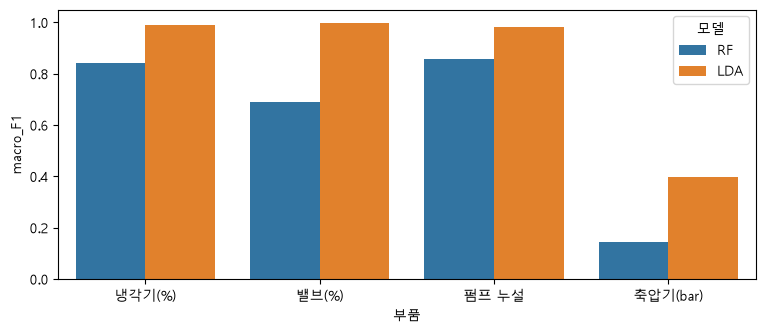

macro_F1           정확도       
모델            LDA     RF    LDA     RF
부품                                    
냉각기(%)      0.989  0.840  0.989  0.849
밸브(%)       0.996  0.689  0.997  0.760
축압기(bar)    0.396  0.143  0.491  0.214
펌프 누설       0.982  0.857  0.987  0.902

In [2]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
FEAT = features(cyc); X = cyc[FEAT].fillna(cyc[FEAT].median()); cv = KFold(5, shuffle=False)
PRED = {}
for c in COMP:
    y = cyc[c].values
    PRED[c] = dict(y=y, RF=cross_val_predict(RandomForestClassifier(300, random_state=SEED, n_jobs=-1), X, y, cv=cv),
                   LDA=cross_val_predict(make_pipeline(StandardScaler(), LDA()), X, y, cv=cv))
perf = pd.DataFrame([dict(부품=COMP[c], 모델=mn, macro_F1=f1_score(d["y"], d[mn], average="macro"), 정확도=accuracy_score(d["y"], d[mn]))
                     for c, d in PRED.items() for mn in ["RF", "LDA"]])
fig, ax = plt.subplots(figsize=(9, 3.5)); sns.barplot(data=perf, x="부품", y="macro_F1", hue="모델", ax=ax); ax.set_ylim(0, 1.05); plt.show()
display(perf.pivot(index="부품", columns="모델", values=["macro_F1", "정확도"]).round(3))

## 2. 기술통계: 맞힘·틀림 교차표

McNemar는 **한 모델만 맞힌 사례**(b, c)만 봅니다. 둘 다 맞히거나 둘 다 틀린 사례는 비교에 쓰지 않습니다.

In [3]:
tabs = {}
for c, d in PRED.items():
    rf, ld = d["RF"] == d["y"], d["LDA"] == d["y"]
    tabs[c] = np.array([[(rf & ld).sum(), (rf & ~ld).sum()], [(~rf & ld).sum(), (~rf & ~ld).sum()]])
    print(f"[{COMP[c]}]  둘 다 맞힘 {tabs[c][0,0]}, RF만 {tabs[c][0,1]}, LDA만 {tabs[c][1,0]}, 둘 다 틀림 {tabs[c][1,1]}")

[냉각기(%)]  둘 다 맞힘 1871, RF만 1, LDA만 310, 둘 다 틀림 23
[밸브(%)]  둘 다 맞힘 1673, RF만 3, LDA만 526, 둘 다 틀림 3
[펌프 누설]  둘 다 맞힘 1981, RF만 7, LDA만 195, 둘 다 틀림 22
[축압기(bar)]  둘 다 맞힘 450, RF만 21, LDA만 632, 둘 다 틀림 1102


## 3. 가정 확인

- **같은 사이클에 대한 짝지은 예측**이어야 합니다. 같은 폴드 분할을 썼으므로 충족합니다.
- 불일치 건수 b + c가 25 이상이면 카이제곱 근사(연속성 보정)를 쓰고, 작으면 정확(이항) 검정을 씁니다.

In [4]:
for c, t in tabs.items(): print(COMP[c], '불일치 b + c =', t[0, 1] + t[1, 0], '→', '카이제곱 근사' if t[0, 1] + t[1, 0] >= 25 else '정확 검정')

냉각기(%) 불일치 b + c = 311 → 카이제곱 근사
밸브(%) 불일치 b + c = 529 → 카이제곱 근사
펌프 누설 불일치 b + c = 202 → 카이제곱 근사
축압기(bar) 불일치 b + c = 653 → 카이제곱 근사


## 4. 정상성과의 관계

이 가설은 특징의 정상성을 직접 검정하지 않습니다. 대신 H05(특징 94% 비정상)와 H06(강한 자기상관) 결과에 따라 **무작위 분할이 아닌 순서 블록 분할로 예측을 만든 것**이 정상성 결과를 반영한 부분입니다. 참고로 두 방식의 점수 차이를 봅니다.

In [5]:
cv_r = KFold(5, shuffle=True, random_state=SEED); rows = []
for c in ["cooler_pct", "accumulator_bar"]:
    y = cyc[c].values
    for mn, mk in [("RF", lambda: RandomForestClassifier(300, random_state=SEED, n_jobs=-1)), ("LDA", lambda: make_pipeline(StandardScaler(), LDA()))]:
        rows.append(dict(부품=COMP[c], 모델=mn, 무작위=f1_score(y, cross_val_predict(mk(), X, y, cv=cv_r), average="macro"),
                         순서블록=f1_score(y, PRED[c][mn], average="macro")))
display(pd.DataFrame(rows).round(3))

,부품,모델,무작위,순서블록
0,냉각기(%),RF,0.999,0.840
1,냉각기(%),LDA,0.999,0.989
2,축압기(bar),RF,0.985,0.143
3,축압기(bar),LDA,0.876,0.396


## 5. 가설검정 (p-값) — McNemar

In [6]:
from statsmodels.stats.contingency_tables import mcnemar
rows = []
for c, t in tabs.items():
    exact = t[0, 1] + t[1, 0] < 25; r = mcnemar(t, exact=exact, correction=True)
    rows.append(dict(부품=COMP[c], RF만=t[0, 1], LDA만=t[1, 0], 통계량=r.statistic, p=r.pvalue))
mc = pd.DataFrame(rows); mc["p_holm"] = holm(mc["p"])
display(mc.style.format({"통계량": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))

,부품,RF만,LDA만,통계량,p,p_holm
0,냉각기(%),1,310,305.0,2.64e-68,5.29e-68
1,밸브(%),3,526,515.1,4.95e-114,1.48e-113
2,펌프 누설,7,195,173.1,1.55e-39,1.55e-39
3,축압기(bar),21,632,569.8,6.11e-126,2.44e-125


## 6. 효과 크기

정확도 차이와 "LDA만 맞힘 / RF만 맞힘" 비율로 봅니다.

In [7]:
mc["정확도차_LDA−RF"] = [perf[(perf.부품 == COMP[c]) & (perf.모델 == "LDA")].정확도.item() - perf[(perf.부품 == COMP[c]) & (perf.모델 == "RF")].정확도.item() for c in COMP]
mc["비율_LDA만/RF만"] = mc["LDA만"] / mc["RF만"].clip(lower=1)
display(mc[["부품", "정확도차_LDA−RF", "비율_LDA만/RF만"]].round(3))

,부품,정확도차_LDA−RF,비율_LDA만/RF만
0,냉각기(%),0.140,310.000
1,밸브(%),0.237,175.333
2,펌프 누설,0.085,27.857
3,축압기(bar),0.277,30.095


## 7. 재확인: 폴드별 macro F1

폴드마다 LDA가 일관되게 나은지 봅니다(폴드 5개로는 Wilcoxon의 최소 p가 0.0625라 검정 대신 그림으로 봅니다).

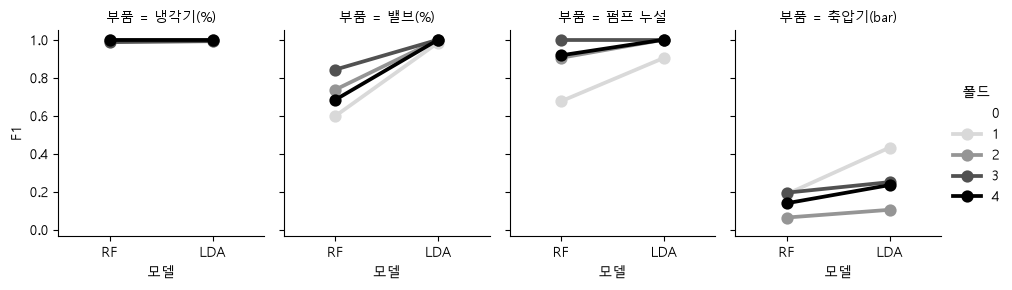

In [8]:
rows = []
for c, d in PRED.items():
    for k, (_, te) in enumerate(cv.split(X)):
        for mn in ["RF", "LDA"]: rows.append(dict(부품=COMP[c], 폴드=k, 모델=mn, F1=f1_score(d["y"][te], d[mn][te], average="macro")))
sns.catplot(data=pd.DataFrame(rows), x="모델", y="F1", col="부품", hue="폴드", kind="point", palette="Greys", height=3, aspect=0.8); plt.show()

## 8. 최종 판정

In [9]:
final = mc[["부품", "RF만", "LDA만", "통계량", "p_holm"]].copy(); final["판정"] = np.where(final.p_holm < ALPHA, "H0 기각 (LDA 우세)", "H0 유지")
display(final.style.format({"통계량": "{:.1f}", "p_holm": "{:.2e}"}))
ca = final[final.부품.isin([COMP["cooler_pct"], COMP["accumulator_bar"]])]
save_result("H08", title="냉각기·축압기 LDA vs RF", test="McNemar (Holm)", stat=" / ".join(f"χ² = {v:.0f}" for v in ca.통계량),
            p=float(ca.p_holm.max()), effect=" / ".join(f"LDA만 {a} vs RF만 {b}" for a, b in zip(ca.LDA만, ca.RF만)),
            verdict="H0 기각" if (ca.p_holm < ALPHA).all() else "H0 유지", note="밸브·펌프도 v1에서 LDA 우세")

,부품,RF만,LDA만,통계량,p_holm,판정
0,냉각기(%),1,310,305.0,5.29e-68,H0 기각 (LDA 우세)
1,밸브(%),3,526,515.1,1.48e-113,H0 기각 (LDA 우세)
2,펌프 누설,7,195,173.1,1.55e-39,H0 기각 (LDA 우세)
3,축압기(bar),21,632,569.8,2.44e-125,H0 기각 (LDA 우세)


저장: results/H08.json


## 9. 해석과 결정

- 냉각기·축압기에서 LDA가 낫다는 가설은 **강하게 지지**됩니다(LDA만 맞힌 사례가 RF만 맞힌 사례의 30~310배).
- **밸브·펌프에서도 LDA가 유의하게 낫습니다**(특징 v1 기준). 11/26 결정(밸브·펌프는 RF)은 특징 v2에서 RF도 충분히 높다는 SOA 결과와 수업 내용을 고려한 것입니다.
- **결정:** 특징 v2 확정(4.1.1) 후 이 노트북을 다시 돌립니다. 그때도 차이가 크면 **밸브·펌프 모델 선택을 재검토**합니다(PM 결정).